# 03 - Baselines and validation scheme

**Goal:** fix how models are compared, measure what the simplest models achieve on each target, and settle which `MM` labels are used for training.

**Inputs:** `data/raw/*.csv` through `miopia.data.load_raw()`, `clean_features` and `make_preprocessor` from notebook 02, and the new module `src/miopia/validation.py`.

**Outputs:** `src/miopia/validation.py` (used by notebooks 04 and 05), and the figures `03_*.png`.

**Assumptions touched:** B1 (metric), B2 (the 8 inconsistent `MM` labels), B17 (how the empty ancestry entries are handled), B12 (what counts as a clear difference) and B13 (what decides when metrics disagree), see `docs/assumptions.md`. The test set is not used in this notebook.

## 1. Setup and data loading

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from miopia.data import load_raw
from miopia.features import clean_features
from miopia.plotting import BLUE, VERMILLION, save_fig, set_style
from miopia.validation import (
    N_REPEATS, N_SPLITS, SUMMARY_METRICS, correct_mm_labels, evaluate, logistic_baseline,
    majority_baseline, make_cv, make_strata, paired_difference,
)

set_style()
pd.set_option("display.width", 140)
TARGETS = ["M", "MM", "Combo", "DCombo"]
X_train_raw, Y_train, _ = load_raw()     # the test rows are not needed here
X_train = clean_features(X_train_raw)
print(f"train {X_train.shape}")

train (132, 32)


## 2. Which rules govern the comparison?

Choosing the rules after seeing the scores would let us pick whatever looks best, so they are written down here. Two parts came later, and are marked as such.

- **Validation.** Repeated stratified 5-fold with 10 repeats. With 132 students and 10 `MM` positives, one split would depend too much on which students land in it, and repeating shows how much the score moves.
- **Selection metric (B1).** Balanced accuracy, with macro-F1 next to it. Accuracy alone rewards ignoring rare classes, but it is still reported because the test labels are graded on it. If balanced accuracy and macro-F1 move in opposite directions, accuracy decides and the report says so (B13); this rule was written after the disagreement seen in section 5.
- **Clear difference (B12).** Two variants run on the same folds. For each repeat we take the difference in mean balanced accuracy. A difference is clear only if its mean over repeats exceeds one standard deviation of those differences. The same bar is applied to the other metrics. It is a stability check across new splits of the same 132 students, not evidence about new students. The requirement for notebook 04 in section 4 was tightened after a review of this notebook.
- **Scoring of label experiments.** Any experiment that changes the training labels is scored against the original labels, so that all variants measure the same target.
- **No leakage.** Every model is a pipeline that starts with `make_preprocessor`, so medians and scaling are learned from the training rows of each fold.

## 3. Does every validation fold contain every class?

**What and why:** a fold with no positives could not measure recall. Each target is stratified on its own column, except `MM`, which is stratified on `Combo` and `MM` together: that keeps the 8 inconsistent students spread across folds, so both label variants are compared on balanced folds. The table gives the smallest and largest count of each class across all validation folds.

In [2]:
strata = {t: make_strata(Y_train, t) for t in TARGETS}

rows = []
for target in TARGETS:
    counts = pd.DataFrame([Y_train[target].iloc[val].value_counts()
                           for _, val in make_cv().split(X_train, strata[target])]).fillna(0).astype(int)
    for cls in sorted(counts.columns):
        rows.append({"target": target, "class": cls, "total": int((Y_train[target] == cls).sum()),
                     "min in a fold": counts[cls].min(), "max in a fold": counts[cls].max()})
print(f"{N_SPLITS} folds x {N_REPEATS} repeats = {N_SPLITS * N_REPEATS} validation folds per target")
inconsistent = (Y_train["Combo"] == "MM") & (Y_train["MM"] == "NO")
per_fold = [int(inconsistent.iloc[val].sum()) for _, val in make_cv().split(X_train, strata["MM"])]
print(f"inconsistent students per MM validation fold: {min(per_fold)} to {max(per_fold)}")
pd.DataFrame(rows).set_index(["target", "class"])

5 folds x 10 repeats = 50 validation folds per target
inconsistent students per MM validation fold: 1 to 2


total  min in a fold  max in a fold
target class                                     
M      NO        44              8              9
       SI        88             17             18
MM     NO       122             24             25
       SI        10              2              2
Combo  C         44              8              9
       M         70             14             14
       MM        18              3              4
DCombo C         44              8              9
       M1        39              7              8
       M2        31              6              7
       MM        18              3              4

**Findings.** Every validation fold contains every class of every target. `MM` has exactly 2 positives per fold, so its fold scores will move a lot. *Decision: this scheme is used for all later comparisons.*

## 4. What do the simplest models achieve?

**What and why:** any later model has to beat these. Three baselines of increasing strength: the majority class, a logistic regression on axial length alone (the strongest predictor found in notebook 01, and a known anatomical correlate of myopia, so the choice does not rest on the labels alone), and a logistic regression on all 32 features with default regularisation. Class weights are balanced to match the selection metric. Here every target is trained and scored on its column as provided; the `MM` label question comes in section 5.

In [3]:
baselines = {"Majority class": (majority_baseline(), X_train),
             "Logistic, axial length only": (logistic_baseline(), X_train[["axial_length"]]),
             "Logistic, all 32 features": (logistic_baseline(), X_train)}

folds = pd.concat([evaluate(model, data, Y_train[t], Y_train[t], strata[t])[0].assign(target=t, model=name)
                   for t in TARGETS for name, (model, data) in baselines.items()], ignore_index=True)

summary = folds.groupby(["target", "model"], sort=False)[SUMMARY_METRICS].mean()
summary.insert(1, "balanced_accuracy_sd", folds.groupby(["target", "model"], sort=False)["balanced_accuracy"].std())
summary.round(2)

balanced_accuracy  balanced_accuracy_sd  macro_f1  accuracy   mcc
target model                                                                                         
M      Majority class                            0.50                  0.00      0.40      0.67  0.00
       Logistic, axial length only               0.77                  0.08      0.75      0.77  0.52
       Logistic, all 32 features                 0.77                  0.10      0.76      0.78  0.53
MM     Majority class                            0.50                  0.00      0.48      0.92  0.00
       Logistic, axial length only               0.81                  0.14      0.65      0.82  0.40
       Logistic, all 32 features                 0.81                  0.15      0.74      0.91  0.52
Combo  Majority class                            0.33                  0.00      0.23      0.53  0.00
       Logistic, axial length only               0.71                  0.07      0.66      0.65  0.45
       Logistic, all 32 features                 0.70                  0.10      0.67      0.67  0.47
DCombo Majority class                            0.25                  0.00      0.12      0.33  0.00
       Logistic, axial length only               0.60                  0.08      0.58      0.56  0.41
       Logistic, all 32 features                 0.51                  0.09      0.50      0.49  0.31

The figure shows the balanced accuracy of each validation fold rather than only the mean, because the spread matters as much as the centre with so few students. The dashed line is what the majority class scores.

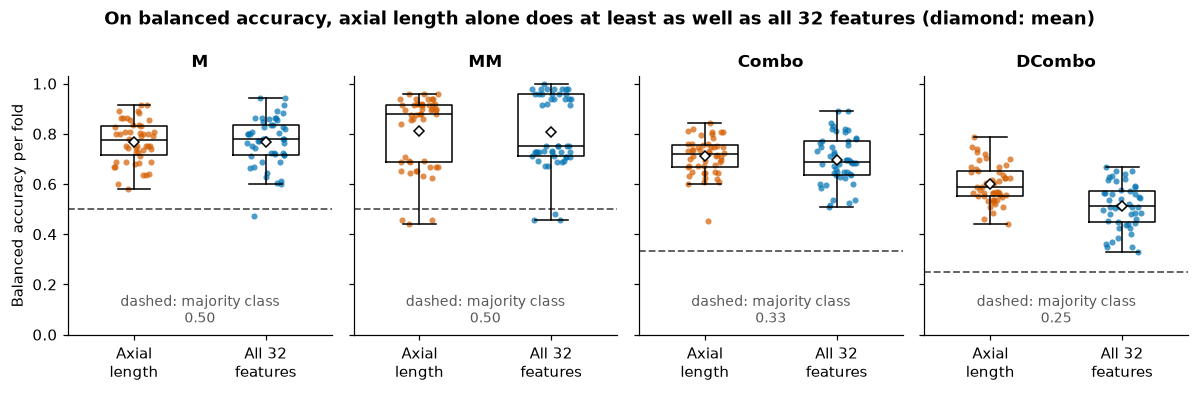

In [4]:
model_colors = {"Logistic, axial length only": VERMILLION, "Logistic, all 32 features": BLUE}
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 4, figsize=(11, 3.6), sharey=True)
for ax, target in zip(axes, TARGETS):
    chance = folds.query("target == @target and model == 'Majority class'")["balanced_accuracy"].mean()
    for x, (name, color) in enumerate(model_colors.items()):
        values = folds.query("target == @target and model == @name")["balanced_accuracy"]
        ax.scatter(x + rng.uniform(-0.15, 0.15, len(values)), values, s=16, color=color, alpha=0.7, linewidths=0)
        ax.boxplot(values, positions=[x], widths=0.5, showfliers=False, medianprops={"color": "black"}, showmeans=True,
                   meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 5})
    ax.axhline(chance, color="0.35", ls="--", lw=1.2, zorder=0)
    ax.text(0.5, 0.03, f"dashed: majority class\n{chance:.2f}", ha="center", va="bottom", fontsize=9, color="0.35")
    ax.set_xticks([0, 1], ["Axial\nlength", "All 32\nfeatures"])
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(0, 1.03)
    ax.set_title(target)
axes[0].set_ylabel("Balanced accuracy per fold")
fig.suptitle("On balanced accuracy, axial length alone does at least as well as all 32 features (diamond: mean)", fontweight="bold")
fig.tight_layout()
save_fig(fig, "03_baselines")
plt.show()

The two logistic models ran on the same folds, so the bar of section 2 can compare them directly. Means hide what happens to each class, so the recall of every class and the pooled out-of-fold confusion matrices of the two multiclass targets are shown as well.

In [5]:
axial_vs_full = {}
for target in TARGETS:
    of_target = folds[folds["target"] == target]
    full = of_target[of_target["model"] == "Logistic, all 32 features"]
    axial = of_target[of_target["model"] == "Logistic, axial length only"]
    axial_vs_full[target] = {f"{m}: {k}": v for m in ["balanced_accuracy", "macro_f1", "accuracy"]
                             for k, v in paired_difference(full, axial, m).items() if k != "sd across repeats"}
print("All 32 features minus axial length only (same folds):")
display(pd.DataFrame(axial_vs_full).T)

recall_columns = [c for c in folds.columns if c.startswith("recall_")]
recalls = folds[folds["model"] != "Majority class"].groupby(["target", "model"], sort=False)[recall_columns].mean()
display(recalls.round(2).astype(object).where(recalls.notna(), "").rename(columns=lambda c: c.removeprefix("recall_")))

for target in ["Combo", "DCombo"]:
    _, predicted = evaluate(logistic_baseline(), X_train[["axial_length"]], Y_train[target], Y_train[target], strata[target])
    truth = np.repeat(Y_train[target].to_numpy(), N_REPEATS)
    print(f"{target}, axial length only: predictions per true class, as a share of that class")
    display(pd.crosstab(truth, predicted.ravel(), rownames=["true"], colnames=["predicted"], normalize="index").round(2))

All 32 features minus axial length only (same folds):


,balanced_accuracy: mean difference,balanced_accuracy: verdict,macro_f1: mean difference,macro_f1: verdict,accuracy: mean difference,accuracy: verdict
M,0.001585,no clear difference,0.006535,no clear difference,0.009886,no clear difference
MM,-0.00395,no clear difference,0.094209,clearly better,0.086011,clearly better
Combo,-0.013889,no clear difference,0.008927,no clear difference,0.02,no clear difference
DCombo,-0.089931,clearly worse,-0.077641,clearly worse,-0.069088,clearly worse


NO    SI     C     M    MM    M1    M2
target model                                                                
M      Logistic, axial length only  0.76  0.78                              
       Logistic, all 32 features    0.73  0.81                              
MM     Logistic, axial length only  0.82   0.8                              
       Logistic, all 32 features    0.93  0.69                              
Combo  Logistic, axial length only              0.66  0.58  0.89            
       Logistic, all 32 features                0.69  0.63  0.76            
DCombo Logistic, axial length only              0.62        0.88  0.39  0.51
       Logistic, all 32 features                0.57        0.69  0.39  0.39

Combo, axial length only: predictions per true class, as a share of that class


predicted,C,M,MM
true,,,
C,0.66,0.34,0.00
M,0.24,0.58,0.18
MM,0.00,0.11,0.89


DCombo, axial length only: predictions per true class, as a share of that class


predicted,C,M1,M2,MM
true,,,,
C,0.62,0.28,0.11,0.00
M1,0.32,0.39,0.28,0.01
M2,0.04,0.24,0.51,0.21
MM,0.00,0.00,0.11,0.89


**Findings.** Both logistic models are far above the majority class on balanced accuracy for every target. On balanced accuracy the full model is clearly worse than axial length alone only on `DCombo`, and elsewhere there is no clear difference, so the other 32 features do not help that metric at this level of regularisation. On `MM`, the full model is clearly better on accuracy and macro-F1, so the choice of reference depends on the metric. On `MM`, the majority class has the highest accuracy of the three models while finding no positives, which is why accuracy alone cannot select the model. The spread between folds is wide, so small gaps mean little. The means also hide weak classes: `M1` and `M2` are the hardest to tell apart in `DCombo`. *Requirement for notebook 04 (B12): beat the better logistic baseline on balanced accuracy without being clearly worse on macro-F1, with accuracy always reported, nested CV for tuned models, and a re-check of the winner on another CV seed. If nothing passes, the logistic baseline stays.* Notebook 04 later extends this test with a second route (B14).

## 5. Experiment: what happens if the 8 inconsistent `MM` labels are corrected?

**What and why:** the 8 students have the other three targets in agreement with myopia magna, and `MM = NO`. Variant A trains on the column as provided. Variant B trains on the corrected column. Both use the full logistic baseline and the same folds, and both are scored against the **original** labels, otherwise they would be measuring different targets. The corrected labels reach the model only through the training rows of each fold. This scoring is hard on B by construction: when B says `SI` for one of the 8, it counts as an error.

In [6]:
Y_corrected = correct_mm_labels(Y_train)
changed = Y_train["MM"] != Y_corrected["MM"]
print(f"labels changed: {int(changed.sum())}; MM = SI goes from {int((Y_train['MM'] == 'SI').sum())} to {int((Y_corrected['MM'] == 'SI').sum())}")
print("other targets unchanged:", Y_train[["M", "Combo", "DCombo"]].equals(Y_corrected[["M", "Combo", "DCombo"]]))
print("other targets of the 8:", {t: Y_train.loc[changed, t].value_counts().to_dict() for t in ["M", "Combo", "DCombo"]})

variant_a, pred_a = evaluate(logistic_baseline(), X_train, Y_train["MM"], Y_train["MM"], strata["MM"])
variant_b, pred_b = evaluate(logistic_baseline(), X_train, Y_corrected["MM"], Y_train["MM"], strata["MM"])

metrics = ["balanced_accuracy", "macro_f1", "accuracy", "mcc", "recall_SI", "recall_NO", "auc", "average_precision"]
comparison = pd.DataFrame({"A: as provided": variant_a[metrics].mean(), "B: corrected": variant_b[metrics].mean()})
differences = pd.DataFrame({m: paired_difference(variant_b, variant_a, m) for m in metrics}).T
comparison.join(differences).astype({"mean difference": float, "sd across repeats": float}).round(3)

labels changed: 8; MM = SI goes from 10 to 18
other targets unchanged: True
other targets of the 8: {'M': {'SI': 8}, 'Combo': {'MM': 8}, 'DCombo': {'MM': 8}}


,A: as provided,B: corrected,mean difference,sd across repeats,verdict
balanced_accuracy,0.808,0.815,0.007,0.037,no clear difference
macro_f1,0.741,0.681,-0.061,0.033,clearly worse
accuracy,0.908,0.853,-0.055,0.011,clearly worse
mcc,0.518,0.434,-0.084,0.067,clearly worse
recall_SI,0.690,0.770,0.080,0.079,clearly better
recall_NO,0.926,0.860,-0.066,0.012,clearly worse
auc,0.883,0.927,0.044,0.015,clearly better
average_precision,0.628,0.656,0.027,0.086,no clear difference


The table shows only one half of the picture, so the next one splits the students into three groups and shows how often each variant says `MM = SI` for them, over all repeats.

In [7]:
groups = {"MM = SI as provided": Y_train["MM"] == "SI",
          "The 8 inconsistent": changed,
          "Everyone else": (Y_train["MM"] == "NO") & ~changed}
pd.DataFrame({"students": {g: int(m.sum()) for g, m in groups.items()},
              "says SI, A": {g: (pred_a[m.values] == "SI").mean() for g, m in groups.items()},
              "says SI, B": {g: (pred_b[m.values] == "SI").mean() for g, m in groups.items()}}).round(2)

,students,"says SI, A","says SI, B"
MM = SI as provided,10,0.69,0.77
The 8 inconsistent,8,0.39,0.89
Everyone else,114,0.05,0.09


Each line in the figure is one repeat of the cross-validation, connecting the score of the same folds under A and B.

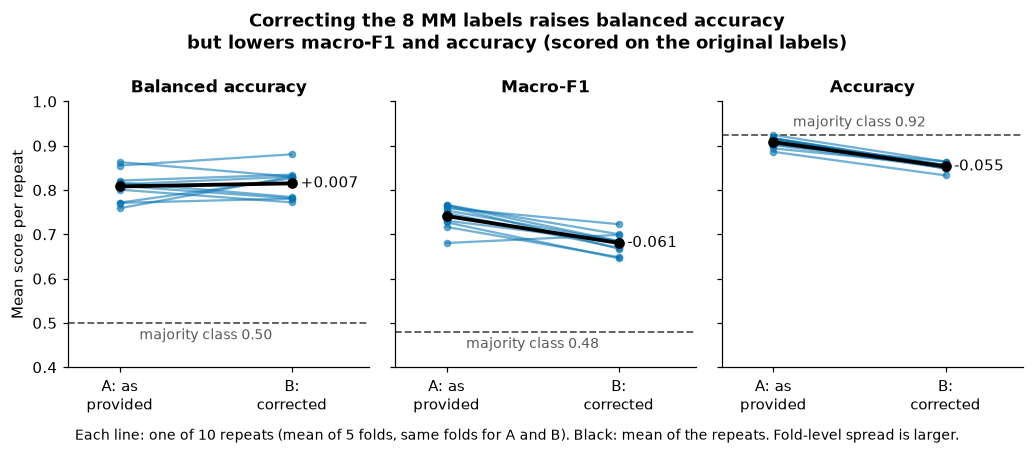

In [8]:
panels = {"balanced_accuracy": "Balanced accuracy", "macro_f1": "Macro-F1", "accuracy": "Accuracy"}
fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.9), sharey=True)
for ax, (metric, label) in zip(axes, panels.items()):
    a = variant_a.groupby("repeat")[metric].mean()
    b = variant_b.groupby("repeat")[metric].mean()
    for va, vb in zip(a, b):
        ax.plot([0, 1], [va, vb], color=BLUE, alpha=0.55, marker="o", ms=4)
    ax.plot([0, 1], [a.mean(), b.mean()], color="black", lw=2.5, marker="o", zorder=5)
    ax.text(1.05, b.mean(), f"{b.mean() - a.mean():+.3f}", va="center")
    majority = folds.query("target == 'MM' and model == 'Majority class'")[metric].mean()
    ax.axhline(majority, color="0.35", ls="--", lw=1.2, zorder=0)
    above = majority > 0.8     # on accuracy the label would otherwise cover the lines
    ax.text(0.5, majority + (0.012 if above else -0.012), f"majority class {majority:.2f}", ha="center",
            va="bottom" if above else "top", fontsize=9, color="0.35")
    ax.set_xticks([0, 1], ["A: as\nprovided", "B:\ncorrected"])
    ax.set_xlim(-0.3, 1.45)
    ax.set_ylim(0.4, 1)
    ax.set_yticks(np.arange(0.4, 1.01, 0.1))
    ax.set_title(label)
axes[0].set_ylabel("Mean score per repeat")
fig.suptitle("Correcting the 8 MM labels raises balanced accuracy\nbut lowers macro-F1 and accuracy (scored on the original labels)", fontweight="bold")
fig.tight_layout()
fig.text(0.5, -0.02, "Each line: one of 10 repeats (mean of 5 folds, same folds for A and B). Black: mean of the repeats. Fold-level spread is larger.", ha="center", fontsize=9)
save_fig(fig, "03_label_variants")
plt.show()

One split can flatter either variant, so the comparison is repeated with 30 different cross-validation seeds, counting how often the bar gives each verdict.

In [9]:
seed_rows = {m: [] for m in ["balanced_accuracy", "macro_f1", "accuracy"]}
for seed in range(30):
    a, _ = evaluate(logistic_baseline(), X_train, Y_train["MM"], Y_train["MM"], strata["MM"], seed=seed)
    b, _ = evaluate(logistic_baseline(), X_train, Y_corrected["MM"], Y_train["MM"], strata["MM"], seed=seed)
    for m in seed_rows:
        seed_rows[m].append(paired_difference(b, a, m))
pd.DataFrame({m: {"lowest mean difference": min(r["mean difference"] for r in rows),
                  "highest mean difference": max(r["mean difference"] for r in rows),
                  **pd.Series([r["verdict"] for r in rows]).value_counts().to_dict()}
              for m, rows in seed_rows.items()}).T.fillna(0).round(3)

,lowest mean difference,highest mean difference,no clear difference,clearly better,clearly worse
balanced_accuracy,-0.008,0.052,29.0,1.0,0.0
macro_f1,-0.080,-0.016,22.0,0.0,8.0
accuracy,-0.056,-0.039,0.0,0.0,30.0


**Findings.** The metrics disagree, and of the three main ones only the accuracy drop is firm: it is clear with every seed, while the other two verdicts depend on the split. B finds more of the original positives and says `SI` more often for the 8 and for everyone else, so more errors are false positives. Accuracy counts every student the same. Balanced accuracy gives the few positives half of the weight, so one extra true positive offsets about 12 false positives. AUC is clearly higher, which counts in favour of the correction, while average precision shows no clear difference, so any gain in ranking is modest; the large moves in the recalls show that much of the change is a different operating point. The fixed 0.5 threshold is only a default, and notebook 04 chooses any `MM` threshold inside CV. On 24 test students the accuracy drop is about 1.5 students on average, and a single test set could differ a lot from that.

The group table explains why the correction is plausible: A says `SI` for the 8 far more often than for everyone else, even though it is trained to say `NO` for them. B's high rate on the 8 is weaker evidence, because B was trained with the other relabelled students as `SI`. This agrees with the 8 looking like the `MM = SI` group, but it does not prove they belong to it (notebook 04, section 8, adds the cornea and finds a difference), and nothing here says how `MM` is written in the test set. If the test column follows the same criterion as the training column, the accuracy drop in the table is what we should expect.

*Decision (B2): correct the 8 labels, so `MM` is trained on the corrected column from notebook 04 on.* The table above scores both variants against the original labels, which assumes those labels are right; that is exactly what is in doubt, so the accuracy drop it shows is partly built into the scoring. Three of the four targets of each of the 8 say myopia magna, and `Combo = MM` and `MM = SI` describe the same condition, so the single disagreeing column is the most likely data-entry error. This is a reasoned judgement taken after seeing these results and the rest of the analysis. The cost is that if the test column was written with the same criterion as the original training column, accuracy on `MM` can be lower than the scores in notebook 04 suggest.

## 6. How should the empty ancestry entries be handled? (B17)

**What and why:** `foreign_ancestors` comes from a free-text column that is empty for about three quarters of the students. An empty entry is read as "no foreign ancestors" (0), which is itself a way of filling a gap. Three variants of the full logistic baseline run on the same folds: the reference (an empty entry counts as 0), drop the feature, or keep it and add a flag for an empty entry. The flag is computed row by row, so it leaks nothing. The labels follow B2 (the 8 `MM` labels corrected). A linear model is only one view, so notebook 04 repeats the check on the chosen models.

In [10]:
ancestry_missing = X_train_raw["origen antepasados (extranjeros)"].isna().astype(float)
variants = {"Drop foreign_ancestors": X_train.drop(columns="foreign_ancestors"),
            "Add missing flag": X_train.assign(ancestry_missing=ancestry_missing)}
print(f"ancestry entry empty: {int(ancestry_missing.sum())} of {len(X_train)}; foreign_ancestors = 1: {int(X_train['foreign_ancestors'].sum())}")
rows = []
for target in TARGETS:
    strata_b2 = make_strata(Y_corrected, target)
    reference, _ = evaluate(logistic_baseline(), X_train, Y_corrected[target], Y_corrected[target], strata_b2)
    for name, data in variants.items():
        result, _ = evaluate(logistic_baseline(), data, Y_corrected[target], Y_corrected[target], strata_b2)
        rows.append({"target": target, "variant": name, **paired_difference(result, reference)})
pd.DataFrame(rows).set_index(["target", "variant"]).astype({"mean difference": float, "sd across repeats": float}).round(3)

ancestry entry empty: 98 of 132; foreign_ancestors = 1: 14


mean difference  sd across repeats              verdict
target variant                                                                        
M      Drop foreign_ancestors            0.002              0.011  no clear difference
       Add missing flag                  0.007              0.033  no clear difference
MM     Drop foreign_ancestors            0.020              0.015       clearly better
       Add missing flag                 -0.005              0.013  no clear difference
Combo  Drop foreign_ancestors            0.012              0.015  no clear difference
       Add missing flag                 -0.010              0.018  no clear difference
DCombo Drop foreign_ancestors            0.022              0.018       clearly better
       Add missing flag                  0.003              0.022  no clear difference

**Findings.** Dropping `foreign_ancestors` is clearly better for the full logistic baseline on `MM` and `DCombo`, by about 0.02 of balanced accuracy, and makes no clear difference on `M` and `Combo`. The flag for empty entries makes no clear difference on any target. The full logistic baseline is not a final model, so this does not decide by itself. *Decision: B17 is settled in notebook 04 (section 7), on the models chosen there.*

## 7. Summary

| # | Finding | Decision / action |
|---|---|---|
| 1 | Every validation fold contains every class, but `MM` has very few positives per fold | Repeated stratified 5-fold with 10 repeats for all comparisons; `src/miopia/validation.py` holds the code |
| 2 | On balanced accuracy, axial length alone does as well as all 32 features in a logistic regression; it is clearly better only on `DCombo` | Notebook 04 must beat the better logistic baseline (requirement in section 4, B12) |
| 3 | On `MM`, the majority class has the best accuracy and finds no positives | Select on balanced accuracy, with macro-F1 next to it (B1); if they disagree, accuracy decides (B13) |
| 4 | Correcting the 8 labels raises balanced accuracy and lowers accuracy and macro-F1, scored against the original labels; only the accuracy drop holds across seeds | Correct the 8 labels and train `MM` on the corrected column from notebook 04 on (B2) |
| 5 | Dropping `foreign_ancestors` helps the full logistic baseline a little on `MM` and `DCombo`; a flag for empty entries makes no clear difference | B17 is settled in notebook 04 on the chosen models; phototype was already dropped in notebook 02 (B9) |

**Next notebook (04):** model comparison per target, including at least one model not seen in class, using the functions in `miopia.validation`.